In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data (1).csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


Проверяем формат столбцов

In [6]:
print(df.dtypes)

Дата            object
Склад            int64
Контрагент      object
Номенклатура    object
Количество       int64
dtype: object


Сразу переведем столбец "Дата" в правильный формат

In [7]:
df['Дата'] = pd.to_datetime(df['Дата'])
print(df['Дата'].dtype)
print(df['Дата'].head())

datetime64[ns]
0   2018-01-04
1   2018-01-04
2   2018-01-04
3   2018-01-04
4   2018-01-04
Name: Дата, dtype: datetime64[ns]


Сгруппируйте данные по дате, посчитайте количество продаж

In [15]:
grouped_df = df.groupby('Дата')['Количество'].sum().reset_index()

print(grouped_df)

          Дата  Количество
0   2018-01-04        3734
1   2018-01-05        3643
2   2018-01-06        3193
3   2018-01-07        3298
4   2018-01-09        4055
..         ...         ...
200 2018-08-26        5302
201 2018-08-28        5983
202 2018-08-29        4969
203 2018-08-30        4648
204 2018-08-31        4570

[205 rows x 2 columns]


Вывести несколько первых строк сгруппированных данных

In [9]:
grouped_df.head()

,Дата,Количество продаж
0,2018-01-04,1840
1,2018-01-05,1301
2,2018-01-06,1306
3,2018-01-07,1322
4,2018-01-09,1719


Нарисуйте график продаж у `grouped_df`

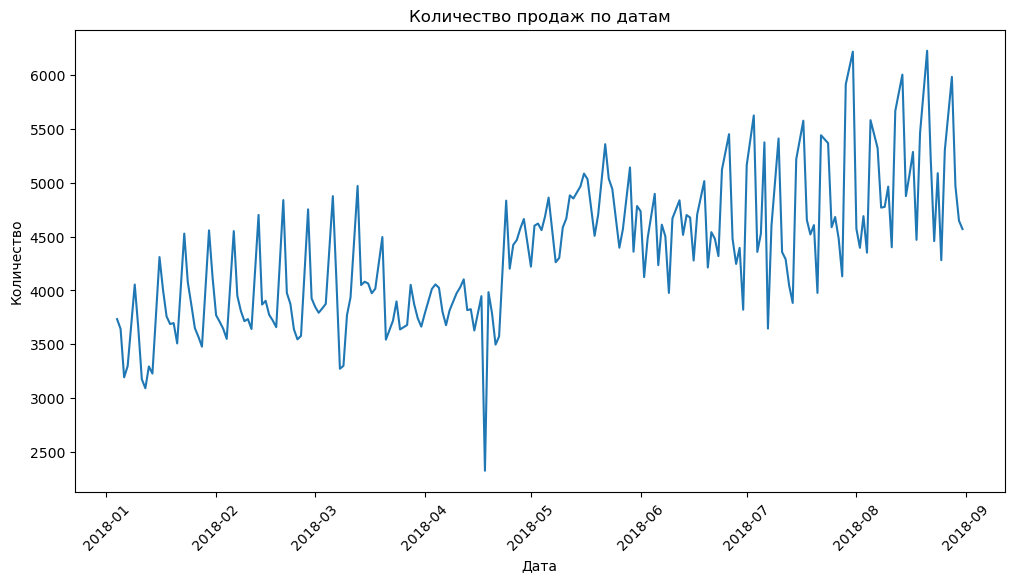

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(grouped_df['Дата'], grouped_df['Количество'])

plt.xlabel('Дата')
plt.ylabel('Количество')
plt.title('Количество продаж по датам')

plt.xticks(rotation=45)
plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

In [ ]:
Самые высокие пики — количество продаж превышает 1700 за день.
Самый низкий спад — примерно в апреле, когда количество продаж опускается ниже 1200.
Общая картина — продажи заметно колеблются от дня к дню, но устойчивого роста или снижения за весь период не видно.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [12]:
Q1 = df['Количество'].quantile(0.25)
Q3 = df['Количество'].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

outliers = df[df['Количество'] > upper_bound]

print(outliers.loc[outliers['Количество'].idxmax()])

Дата            2018-06-28 00:00:00
Склад                             1
Контрагент              address_208
Номенклатура              product_0
Количество                      200
Name: 218822, dtype: object


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [17]:
# Отбираем нужные строки
filtered_df = df[
    (df['Склад'] == 3) &
    (df['Дата'].dt.month.isin([6, 7, 8])) &
    (df['Дата'].dt.dayofweek == 2)
]

# Группируем по товару и суммируем количество
grouped_df = filtered_df.groupby('Номенклатура')['Количество'].sum()

# Выводим самый продаваемый товар
print(grouped_df.sort_values(ascending=False).head(1))

Номенклатура
product_1    2267
Name: Количество, dtype: int64


Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

In [37]:
weather_df['Дата'] = pd.to_datetime(
    weather_df['Местное время в Астане'],
    format='%d.%m.%Y %H:%M',
    errors='coerce'
)

weather_df['T'] = pd.to_numeric(weather_df['T'], errors='coerce')

weather_df = weather_df.dropna(subset=['Дата', 'T']).copy()

weather_df['Дата'] = weather_df['Дата'].dt.normalize()

In [38]:
temperature_df = weather_df.groupby('Дата')['T'].mean().reset_index()

temperature_df.head()

,Дата,T
0,2018-01-01,-9.4625
1,2018-01-02,-9.5125
2,2018-01-03,-11.4625
3,2018-01-04,-14.0750
4,2018-01-05,-16.8625


In [42]:
grouped_df = df.groupby('Дата').size().reset_index(name='Количество')

grouped_df.head()

,Дата,Количество
0,2018-01-04,1840
1,2018-01-05,1301
2,2018-01-06,1306
3,2018-01-07,1322
4,2018-01-09,1719


In [30]:
temperature_df = weather_df.groupby(
    weather_df['Дата'].dt.normalize()
)['T'].mean().reset_index()

temperature_df.columns = ['Дата', 'T']

temperature_df.head()

,Дата,T
0,2018-01-01,-9.4625
1,2018-01-02,-9.5125
2,2018-01-03,-11.4625
3,2018-01-04,-14.0750
4,2018-01-05,-16.8625


In [43]:
grouped_df['Дата'] = pd.to_datetime(grouped_df['Дата']).dt.normalize()

merged_df = pd.merge(
    grouped_df,
    temperature_df,
    on='Дата',
    how='inner'
)

merged_df.head()

,Дата,Количество,T
0,2018-01-04,1840,-14.0750
1,2018-01-05,1301,-16.8625
2,2018-01-06,1306,-13.3000
3,2018-01-07,1322,-12.7500
4,2018-01-09,1719,-6.2500
